# Team Rhone: Wine Review Authorship EDA

This notebook explores whether wine reviewers have distinguishable writing styles, while checking whether country, variety, or other wine characteristics may be giving the model easy authorship clues.

**Before running:** upload the Kaggle wine-review CSV to the same folder as this notebook, then update `INPUT_FILE` in the settings section below if its filename differs.


## What this produces

- Missingness and duplicate-review checks
- Author-review count distribution
- A balanced sample of selected authors
- Country and variety heatmaps by reviewer
- Score and review-length comparisons
- Author-specific TF-IDF terms
- A check for metadata words that may appear directly in review text


Loaded 129,971 rows and 14 columns.
Columns: Unnamed: 0, country, description, designation, points, price, province, region_1, region_2, taster_name, taster_twitter_handle, title, variety, winery


,metric,value
0,rows,129971
1,columns,14
2,duplicate_full_rows,0
3,duplicate_descriptions,20026


,column,missing_percent,missing_count
0,region_2,61.136715,79460
1,designation,28.825661,37465
2,taster_twitter_handle,24.015357,31213
3,taster_name,20.192197,26244
4,region_1,16.347493,21247
5,price,6.921544,8996
6,country,0.048472,63
7,province,0.048472,63
8,variety,0.000769,1
9,Unnamed: 0,0.000000,0


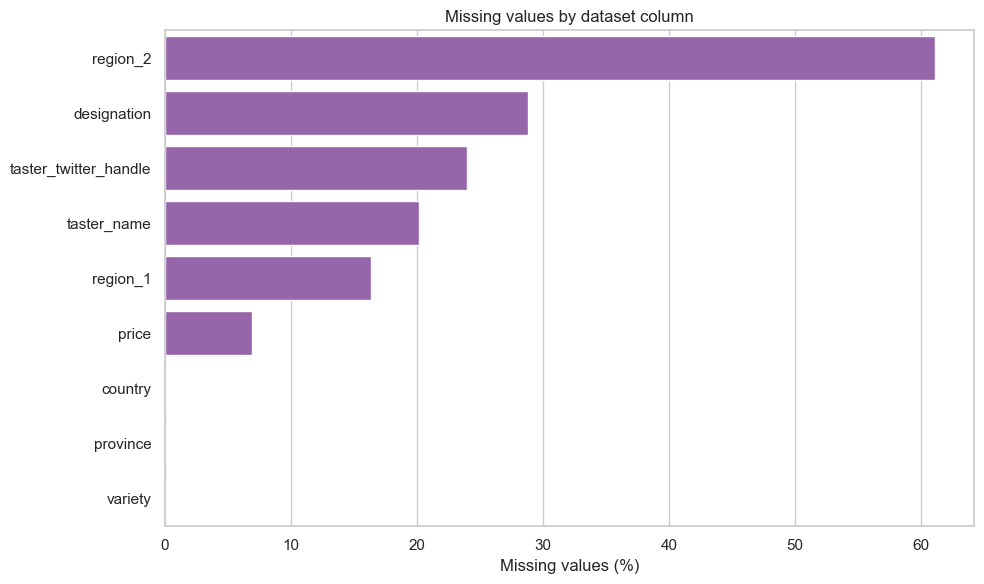


Top 20 reviewers by usable review count:


,author,review_count
0,Roger Voss,25514
1,Michael Schachner,15134
2,Kerin O’Keefe,10776
3,Virginie Boone,9537
4,Paul Gregutt,9532
5,Matt Kettmann,6332
6,Joe Czerwinski,5147
7,Sean P. Sullivan,4966
8,Anna Lee C. Iijima,4415
9,Jim Gordon,4177


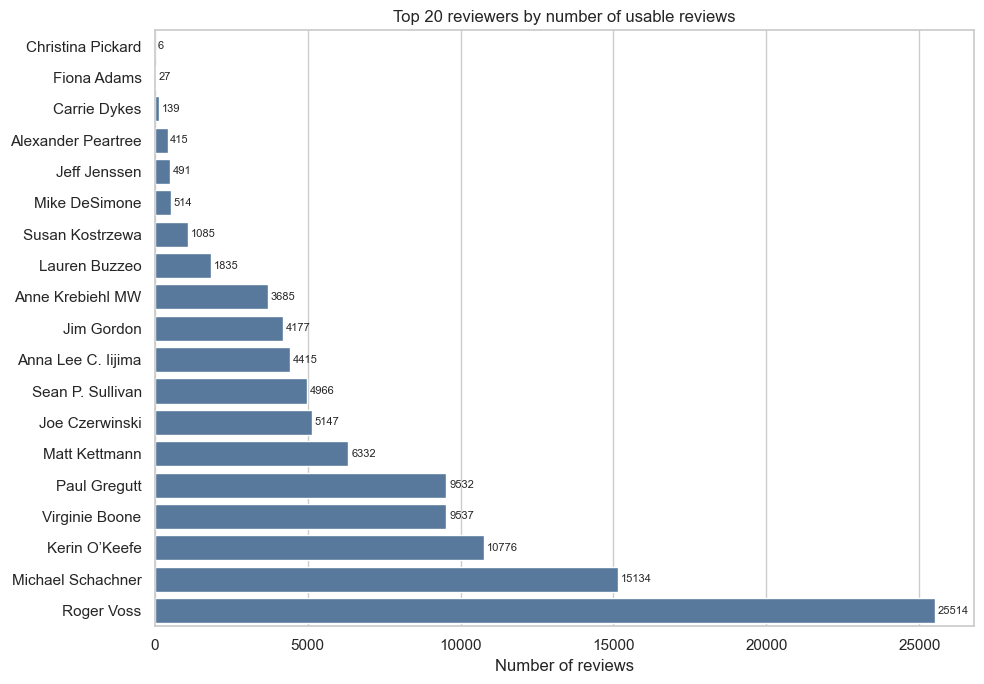

Selected 8 authors; sampled 500 reviews per author.


,selected_author,usable_reviews
0,Roger Voss,25514
1,Michael Schachner,15134
2,Kerin O’Keefe,10776
3,Virginie Boone,9537
4,Paul Gregutt,9532
5,Matt Kettmann,6332
6,Joe Czerwinski,5147
7,Sean P. Sullivan,4966


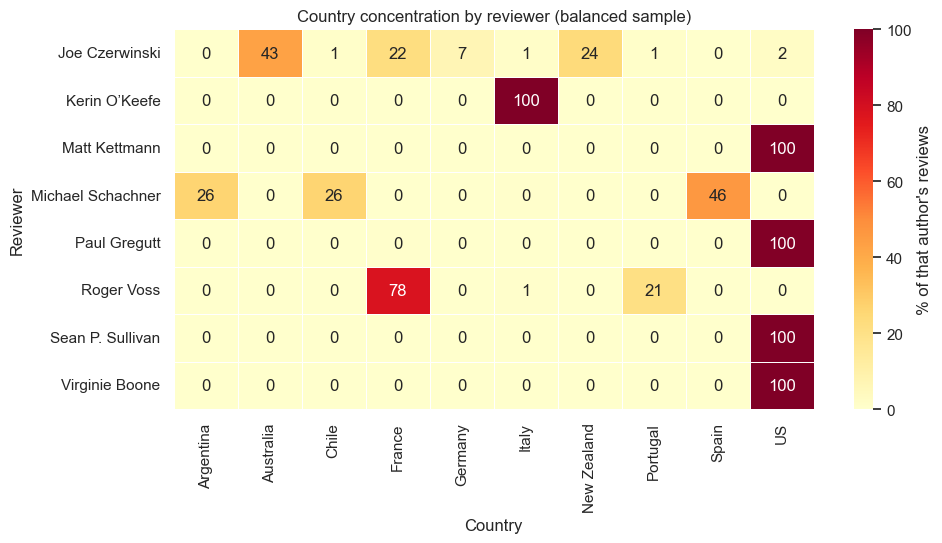

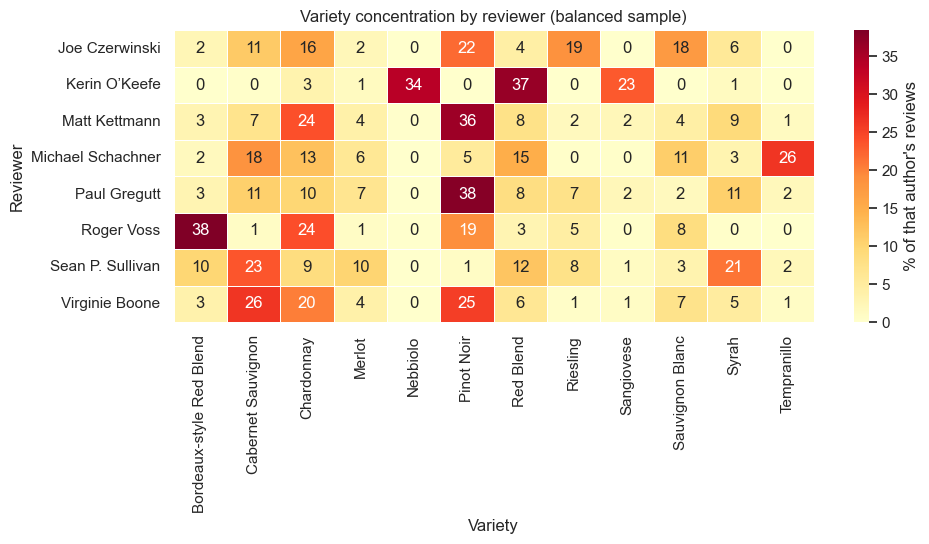


Reviewer score and length summary (balanced sample):


,taster_name,word_count_count,word_count_mean,word_count_median,word_count_std,points_count,points_mean,points_median,points_std
0,Joe Czerwinski,500,42.902,43.0,10.971469,500,88.754,89.0,2.883420
1,Kerin O’Keefe,500,39.910,39.0,8.398987,500,88.978,89.0,2.343609
2,Matt Kettmann,500,49.516,49.0,8.792745,500,90.172,90.0,2.591495
3,Michael Schachner,500,43.886,44.0,9.511990,500,86.768,87.0,2.896023
4,Paul Gregutt,500,44.100,43.0,12.887598,500,88.954,89.0,2.843247
5,Roger Voss,500,37.078,36.0,9.549571,500,88.690,88.0,3.050329
6,Sean P. Sullivan,500,37.670,36.0,11.923147,500,88.702,88.0,2.474154
7,Virginie Boone,500,40.992,40.0,11.199052,500,89.032,90.0,3.112934


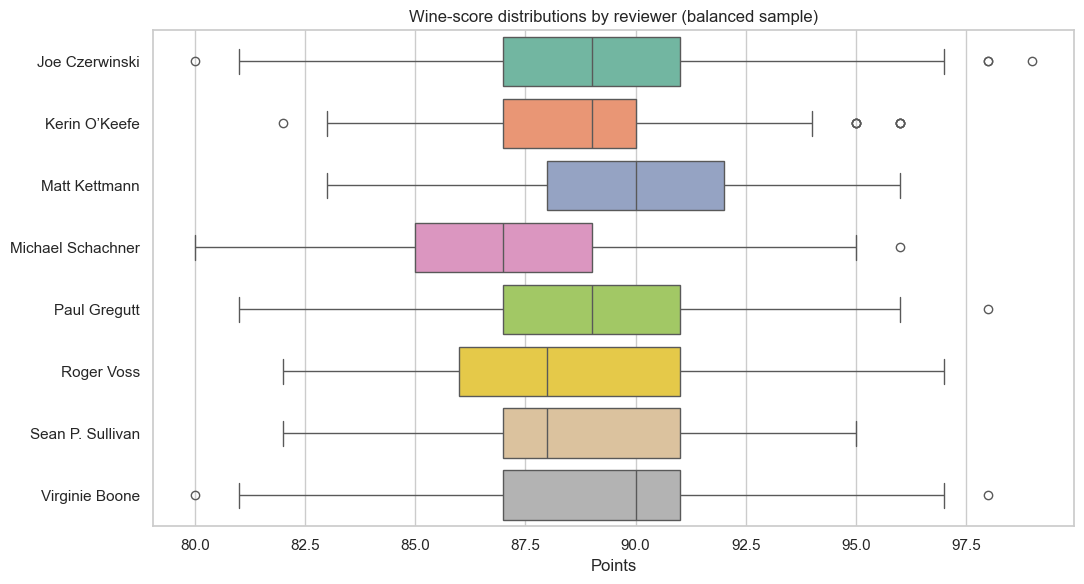

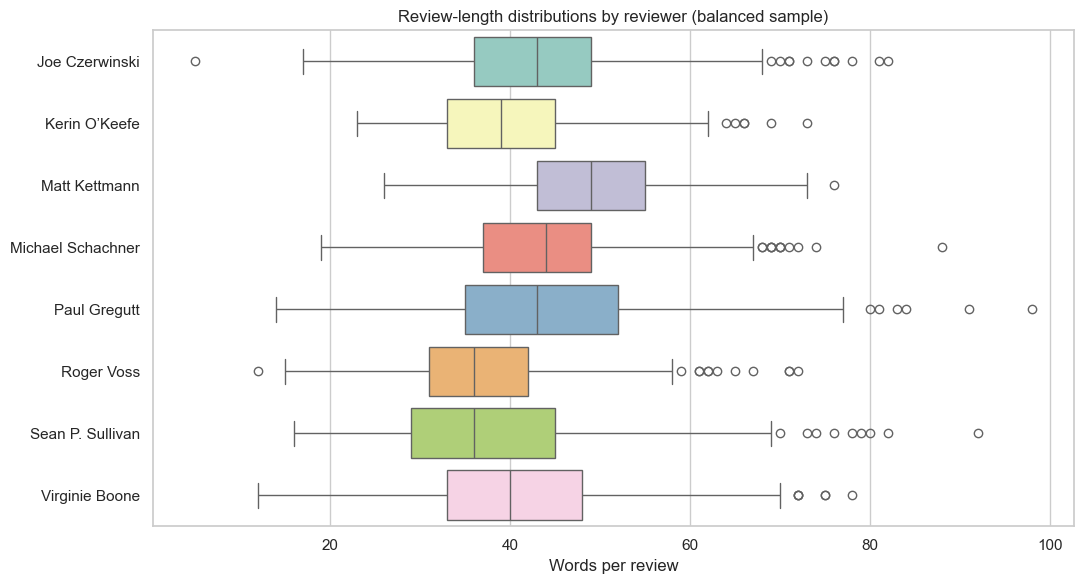


Top TF-IDF terms by reviewer:


,author,rank,term,mean_tfidf
0,Roger Voss,1,wine,0.086437
1,Roger Voss,2,drink,0.048358
2,Roger Voss,3,acidity,0.048321
3,Roger Voss,4,fruits,0.043695
4,Roger Voss,5,ripe,0.040332
...,...,...,...,...
115,Sean P. Sullivan,11,herbs,0.024086
116,Sean P. Sullivan,12,cherry,0.023656
117,Sean P. Sullivan,13,finish,0.023527
118,Sean P. Sullivan,14,lead,0.023067


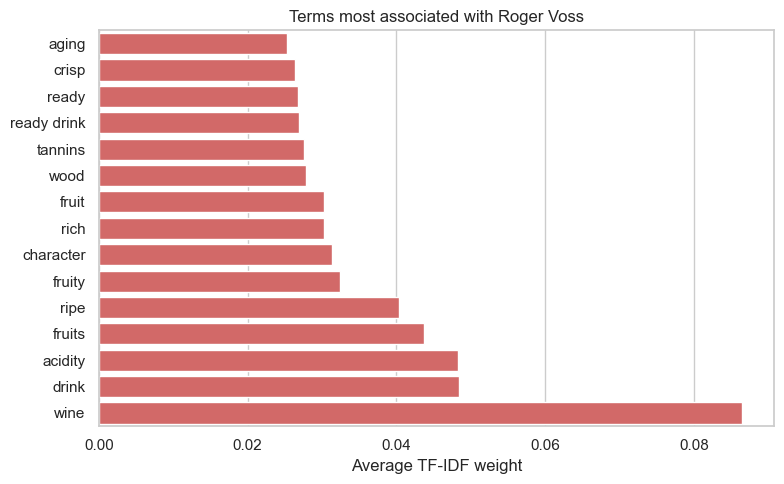

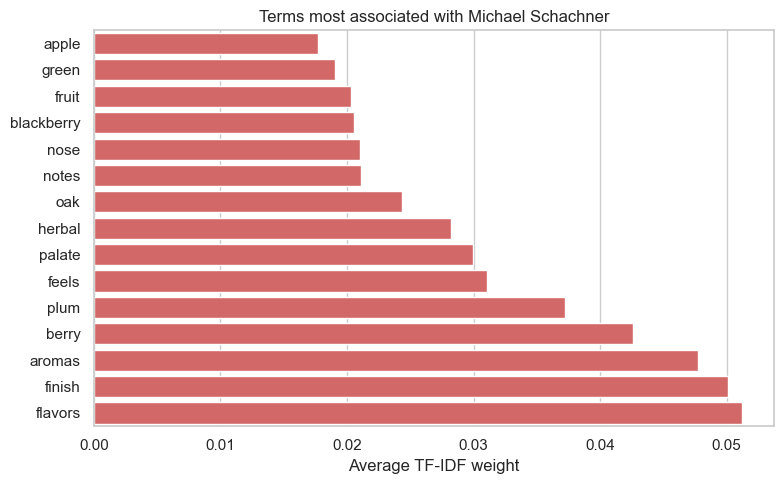

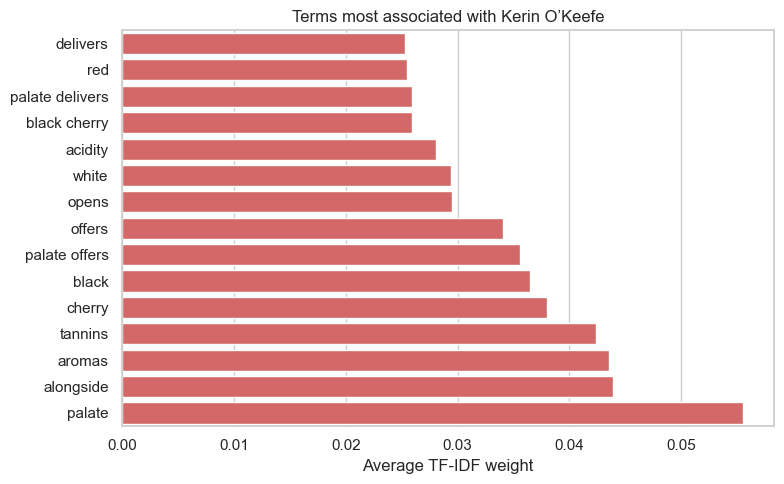

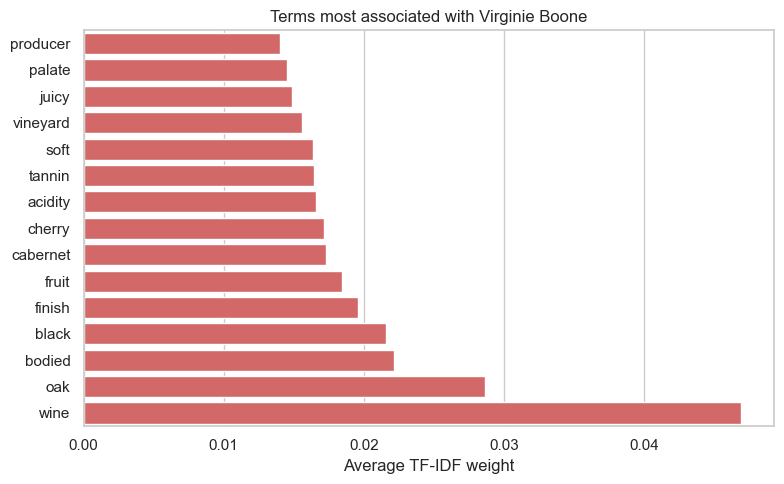

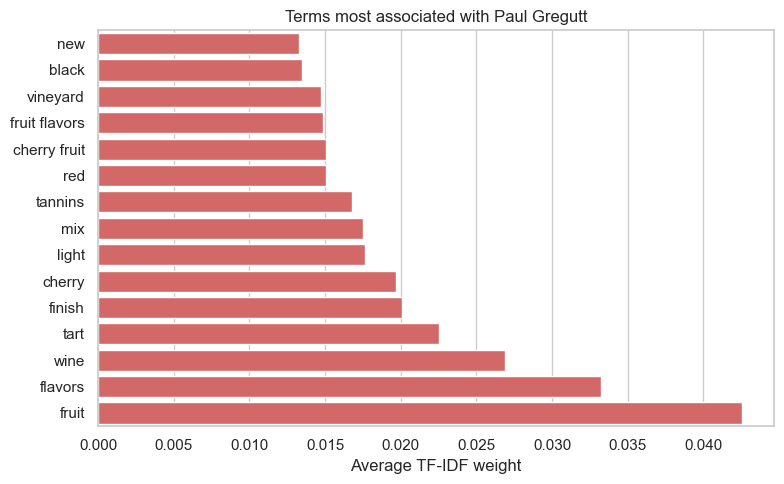

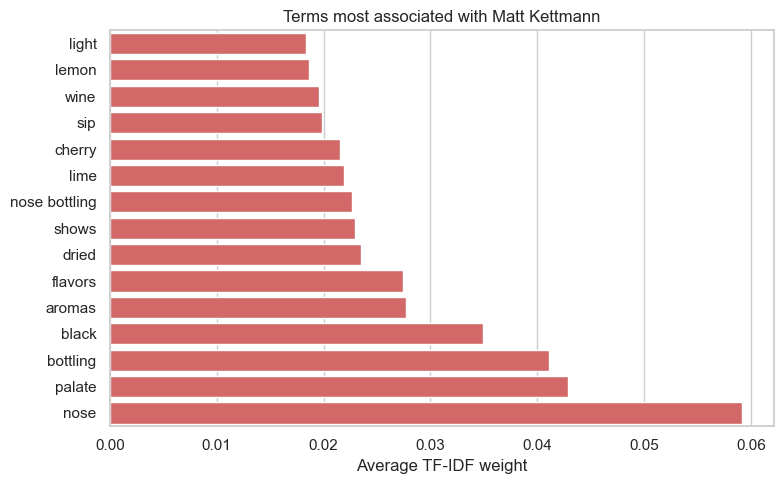

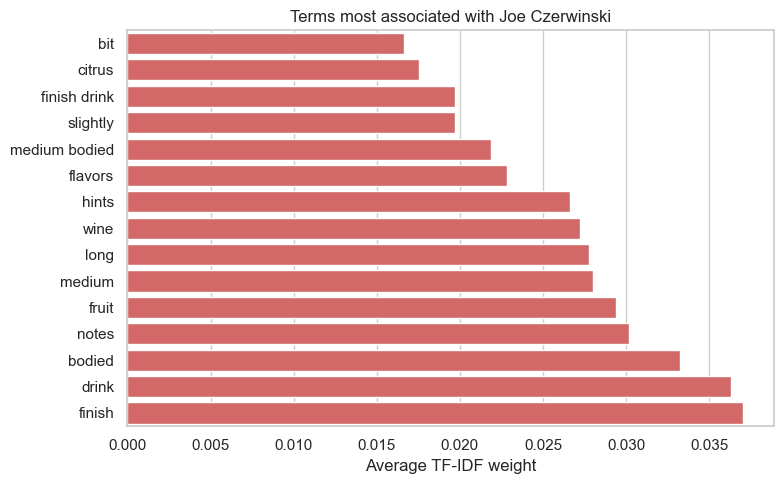

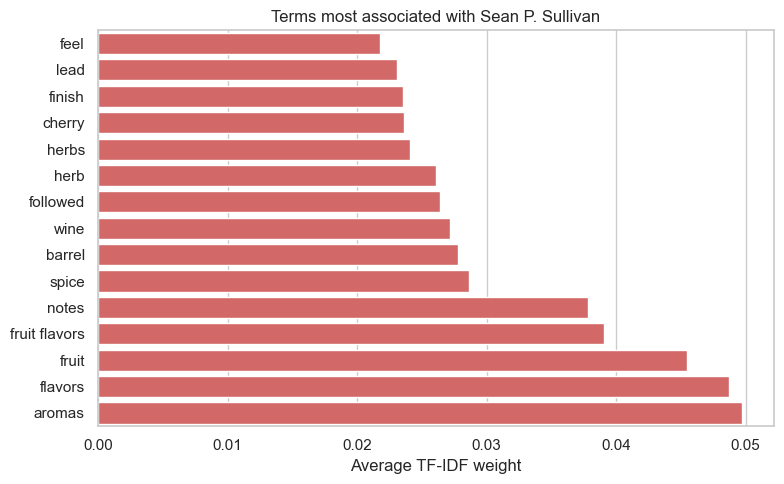


How often a review directly mentions its own metadata:


,author,reviews,country_mentioned_percent,province_mentioned_percent,variety_mentioned_percent
0,Joe Czerwinski,500,4.2,6.0,27.6
1,Kerin O’Keefe,500,0.6,0.4,9.4
2,Matt Kettmann,500,53.2,2.0,8.4
3,Michael Schachner,500,4.8,0.8,21.4
4,Paul Gregutt,500,49.0,10.6,26.6
5,Roger Voss,500,0.6,7.2,8.8
6,Sean P. Sullivan,500,29.6,1.8,6.2
7,Virginie Boone,500,48.2,1.0,13.2



Duplicate-description check:


,metric,value
0,usable_reviews,103727
1,rows_in_duplicate_description_groups,17362
2,unique_duplicated_descriptions,8678



Done. Main files to inspect:
 - team_rhone_eda_output/01_missingness.png
 - team_rhone_eda_output/02_author_review_counts_top20.png
 - team_rhone_eda_output/03_country_heatmap.png
 - team_rhone_eda_output/03_variety_heatmap.png
 - team_rhone_eda_output/04_points_by_author.png
 - team_rhone_eda_output/05_word_count_by_author.png
 - team_rhone_eda_output/top_tfidf_terms_by_author.csv
 - team_rhone_eda_output/metadata_terms_mentioned_in_text.csv


In [3]:
"""Team Rhone EDA: wine-review authorship attribution.

Run from the folder containing the Kaggle wine-review CSV:
    python team_rhone_eda.py

Change INPUT_FILE below if your downloaded CSV has a different name.
Outputs are saved in team_rhone_eda_output/.
"""

from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

try:
    from IPython.display import display
except ImportError:  # Keeps the .py script usable outside Jupyter too.
    def display(value):
        print(value)


# ----------------------------- SETTINGS -----------------------------------
INPUT_FILE = "winemag-data-130k-v2.csv"  # e.g. "winemag-data_first150k.csv"
OUTPUT_DIR = Path("team_rhone_eda_output")

MIN_REVIEWS_PER_AUTHOR = 500  # authors need at least this many valid reviews
N_AUTHORS = 8                 # analyze the most prolific eligible authors
REVIEWS_PER_AUTHOR = 500      # equal-size sample for author comparisons
RANDOM_STATE = 4401
TOP_COUNTRIES = 10
TOP_VARIETIES = 12
TOP_TERMS = 15

sns.set_theme(style="whitegrid", context="notebook")


def safe_name(text: str) -> str:
    """Make author names safe to use in filenames."""
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_")


def savefig(name: str) -> None:
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight")
    # Show every chart inline when this code is run in Jupyter/Colab.
    plt.show()
    plt.close()


def annotate_bar_counts(ax) -> None:
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", padding=2, fontsize=8)


def main() -> None:
    OUTPUT_DIR.mkdir(exist_ok=True)
    input_path = Path(INPUT_FILE)
    if not input_path.exists():
        raise FileNotFoundError(
            f"Could not find {INPUT_FILE!r}. Put this script in the same folder as "
            "your CSV or change INPUT_FILE at the top of the script."
        )

    df = pd.read_csv(input_path)
    print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")
    print("Columns:", ", ".join(df.columns))

    required = {"taster_name", "description"}
    missing_required = required - set(df.columns)
    if missing_required:
        raise ValueError(f"This dataset is missing required columns: {missing_required}")

    # ----------------------------------------------------------------------
    # 1. Dataset overview and missingness
    # ----------------------------------------------------------------------
    overview = pd.DataFrame({
        "metric": ["rows", "columns", "duplicate_full_rows", "duplicate_descriptions"],
        "value": [
            len(df),
            len(df.columns),
            int(df.duplicated().sum()),
            int(df["description"].duplicated(keep=False).sum()),
        ],
    })
    overview.to_csv(OUTPUT_DIR / "dataset_overview.csv", index=False)
    display(overview)

    # ``names=`` in reset_index is only available in newer pandas releases.
    # This form works in both older Colab/Jupyter environments and current pandas.
    missingness = (
        df.isna().mean().mul(100).sort_values(ascending=False)
        .rename("missing_percent").reset_index().rename(columns={"index": "column"})
    )
    missingness["missing_count"] = df.isna().sum().reindex(missingness["column"]).to_numpy()
    missingness.to_csv(OUTPUT_DIR / "missingness.csv", index=False)
    display(missingness)

    plt.figure(figsize=(10, 6))
    plot_missing = missingness[missingness["missing_percent"] > 0]
    sns.barplot(data=plot_missing, x="missing_percent", y="column", color="#9b59b6")
    plt.title("Missing values by dataset column")
    plt.xlabel("Missing values (%)")
    plt.ylabel("")
    savefig("01_missingness.png")

    # Keep only usable text and named authors. Strip blank strings too.
    clean = df.dropna(subset=["taster_name", "description"]).copy()
    clean["taster_name"] = clean["taster_name"].astype(str).str.strip()
    clean["description"] = clean["description"].astype(str).str.strip()
    clean = clean[(clean["taster_name"] != "") & (clean["description"] != "")].copy()
    clean["word_count"] = clean["description"].str.findall(r"\b\w+\b").str.len()

    # ----------------------------------------------------------------------
    # 2. Author imbalance and a balanced analysis sample
    # ----------------------------------------------------------------------
    author_counts = clean["taster_name"].value_counts().rename_axis("author").reset_index(name="review_count")
    author_counts.to_csv(OUTPUT_DIR / "author_review_counts_all.csv", index=False)
    print("\nTop 20 reviewers by usable review count:")
    display(author_counts.head(20))

    top_plot = author_counts.head(20).sort_values("review_count")
    plt.figure(figsize=(10, 7))
    ax = sns.barplot(data=top_plot, x="review_count", y="author", color="#4c78a8")
    annotate_bar_counts(ax)
    plt.title("Top 20 reviewers by number of usable reviews")
    plt.xlabel("Number of reviews")
    plt.ylabel("")
    savefig("02_author_review_counts_top20.png")

    eligible = author_counts.loc[author_counts["review_count"] >= MIN_REVIEWS_PER_AUTHOR, "author"]
    selected_authors = eligible.head(N_AUTHORS).tolist()
    if len(selected_authors) < 2:
        raise ValueError("Fewer than two authors meet MIN_REVIEWS_PER_AUTHOR. Lower that setting.")

    selected_all = clean[clean["taster_name"].isin(selected_authors)].copy()
    available_min = selected_all["taster_name"].value_counts().min()
    sample_size = min(REVIEWS_PER_AUTHOR, available_min)
    balanced = (
        selected_all.groupby("taster_name", group_keys=False)
        .sample(n=sample_size, random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )
    balanced.to_csv(OUTPUT_DIR / "balanced_author_sample.csv", index=False)
    pd.DataFrame({"selected_author": selected_authors}).to_csv(
        OUTPUT_DIR / "selected_authors.csv", index=False
    )
    print(f"Selected {len(selected_authors)} authors; sampled {sample_size} reviews per author.")
    display(pd.DataFrame({"selected_author": selected_authors, "usable_reviews": [
        int((clean["taster_name"] == author).sum()) for author in selected_authors
    ]}))

    # ----------------------------------------------------------------------
    # 3. Confound checks: country and variety by author
    # ----------------------------------------------------------------------
    def plot_author_composition(column: str, top_n: int, file_prefix: str, label: str) -> None:
        if column not in balanced.columns:
            print(f"Skipping {column}: column not found.")
            return
        top_values = balanced[column].dropna().value_counts().head(top_n).index
        subset = balanced[balanced[column].isin(top_values)].copy()
        table = pd.crosstab(subset["taster_name"], subset[column], normalize="index") * 100
        table.to_csv(OUTPUT_DIR / f"{file_prefix}_by_author_percent.csv")

        plt.figure(figsize=(max(10, top_n * 0.8), max(4, len(selected_authors) * 0.7)))
        sns.heatmap(table, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=.4,
                    cbar_kws={"label": "% of that author's reviews"})
        plt.title(f"{label} concentration by reviewer (balanced sample)")
        plt.xlabel(label)
        plt.ylabel("Reviewer")
        savefig(f"03_{file_prefix}_heatmap.png")

    plot_author_composition("country", TOP_COUNTRIES, "country", "Country")
    plot_author_composition("variety", TOP_VARIETIES, "variety", "Variety")

    # ----------------------------------------------------------------------
    # 4. Score and review-length differences
    # ----------------------------------------------------------------------
    summary_cols = ["word_count"] + (["points"] if "points" in balanced.columns else [])
    author_summary = balanced.groupby("taster_name")[summary_cols].agg(["count", "mean", "median", "std"])
    author_summary.columns = ["_".join(col) for col in author_summary.columns]
    author_summary.reset_index().to_csv(OUTPUT_DIR / "author_score_length_summary.csv", index=False)
    print("\nReviewer score and length summary (balanced sample):")
    display(author_summary.reset_index())

    if "points" in balanced.columns:
        plt.figure(figsize=(11, 6))
        sns.boxplot(data=balanced, x="points", y="taster_name", hue="taster_name", legend=False, palette="Set2")
        plt.title("Wine-score distributions by reviewer (balanced sample)")
        plt.xlabel("Points")
        plt.ylabel("")
        savefig("04_points_by_author.png")

    plt.figure(figsize=(11, 6))
    sns.boxplot(data=balanced, x="word_count", y="taster_name", hue="taster_name", legend=False, palette="Set3")
    plt.title("Review-length distributions by reviewer (balanced sample)")
    plt.xlabel("Words per review")
    plt.ylabel("")
    savefig("05_word_count_by_author.png")

    # ----------------------------------------------------------------------
    # 5. Author-specific vocabulary with TF-IDF
    # ----------------------------------------------------------------------
    vectorizer = TfidfVectorizer(
        stop_words="english", lowercase=True, ngram_range=(1, 2), min_df=3, max_df=0.85
    )
    matrix = vectorizer.fit_transform(balanced["description"])
    terms = np.array(vectorizer.get_feature_names_out())
    tfidf_rows = []
    for author in selected_authors:
        author_mask = balanced["taster_name"].eq(author).to_numpy()
        # Average TF-IDF means a term must be consistently important, not merely appear once.
        mean_weights = np.asarray(matrix[author_mask].mean(axis=0)).ravel()
        for rank, idx in enumerate(mean_weights.argsort()[::-1][:TOP_TERMS], start=1):
            tfidf_rows.append({
                "author": author,
                "rank": rank,
                "term": terms[idx],
                "mean_tfidf": mean_weights[idx],
            })
    top_terms = pd.DataFrame(tfidf_rows)
    top_terms.to_csv(OUTPUT_DIR / "top_tfidf_terms_by_author.csv", index=False)
    print("\nTop TF-IDF terms by reviewer:")
    display(top_terms)

    # One readable bar chart per reviewer.
    for author, group in top_terms.groupby("author", sort=False):
        plot = group.sort_values("mean_tfidf")
        plt.figure(figsize=(8, 5))
        sns.barplot(data=plot, x="mean_tfidf", y="term", color="#e45756")
        plt.title(f"Terms most associated with {author}")
        plt.xlabel("Average TF-IDF weight")
        plt.ylabel("")
        savefig(f"06_tfidf_{safe_name(author)}.png")

    # ----------------------------------------------------------------------
    # 6. Possible giveaway clues inside review text
    # ----------------------------------------------------------------------
    # This does NOT prove leakage, but flags reviews that literally mention metadata.
    clue_rows = []
    for author, group in balanced.groupby("taster_name"):
        text = group["description"].str.lower()
        row = {"author": author, "reviews": len(group)}
        for column in ["country", "province", "variety"]:
            if column not in group.columns:
                continue
            mentions = []
            for review, value in zip(text, group[column]):
                if pd.isna(value) or not str(value).strip():
                    mentions.append(False)
                else:
                    # Whole-phrase match avoids treating short strings as arbitrary substrings.
                    mentions.append(bool(re.search(r"(?<!\\w)" + re.escape(str(value).lower()) + r"(?!\\w)", review)))
            row[f"{column}_mentioned_percent"] = 100 * np.mean(mentions)
        clue_rows.append(row)
    clue_report = pd.DataFrame(clue_rows)
    clue_report.to_csv(OUTPUT_DIR / "metadata_terms_mentioned_in_text.csv", index=False)
    print("\nHow often a review directly mentions its own metadata:")
    display(clue_report)

    # ----------------------------------------------------------------------
    # 7. Duplicate descriptions: important before train/test modeling
    # ----------------------------------------------------------------------
    duplicate_descriptions = clean[clean.duplicated("description", keep=False)].sort_values("description")
    duplicate_descriptions.to_csv(OUTPUT_DIR / "duplicate_descriptions.csv", index=False)
    duplicate_summary = pd.DataFrame({
        "metric": ["usable_reviews", "rows_in_duplicate_description_groups", "unique_duplicated_descriptions"],
        "value": [len(clean), len(duplicate_descriptions), duplicate_descriptions["description"].nunique()],
    })
    duplicate_summary.to_csv(OUTPUT_DIR / "duplicate_description_summary.csv", index=False)
    print("\nDuplicate-description check:")
    display(duplicate_summary)

    print("\nDone. Main files to inspect:")
    for filename in [
        "01_missingness.png",
        "02_author_review_counts_top20.png",
        "03_country_heatmap.png",
        "03_variety_heatmap.png",
        "04_points_by_author.png",
        "05_word_count_by_author.png",
        "top_tfidf_terms_by_author.csv",
        "metadata_terms_mentioned_in_text.csv",
    ]:
        print(" -", OUTPUT_DIR / filename)


if __name__ == "__main__":
    main()


**Key EDA Takeaways**
- 8 eligible reviewers selected; 500 reviews sampled per reviewer.
- Balanced modeling sample: 4,000 total reviews.
- Selected reviewers range from 4,968 reviews (Sean P. Sullivan) to 25,514 (Roger Voss) in the full usable dataset.
- About 20% of records are missing taster_name and cannot be used for authorship prediction.
country, province, and variety have little missing data; region_2 is about 62% missing.
- Reviewer coverage is geographically concentrated: Italy (Kerin O’Keefe), U.S. (Matt Kettmann, Paul Gregutt, Sean P. Sullivan, Virginie Boone), France/Portugal (Roger Voss), and Argentina/Chile/Spain (Michael Schachner).
- Review length and score distributions differ across reviewers.
- Country, variety, score, review-length, and TF-IDF vocabulary outputs created for each selected reviewer.